# Внедрение овербукинга в сеть отелей: прогнозирование отмены бронирования

### Бизнес-задача
Оценить возможность прогнозировать вероятность отмены бронирования клиента и использовать этот прогноз как дополнительный инструмент при планировании загрузки отеля.

### Ограничения проекта
- используем признаки, доступные до момента заселения;
- отдельно оцениваем качество прогноза;
- результат модели не является готовым расчётом оптимального объёма овербукинга.

**Данные:** исторические бронирования отелей за 2015–2017 годы.

**Инструменты:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.

## План анализа

1. Загрузить и проверить данные.
2. Провести предобработку.
3. Посмотреть долю отменённых бронирований.
4. Провести описательный и диагностический анализ.
5. Построить логистическую регрессию.
6. Получить вероятность отмены бронирования.
7. Оценить качество модели.
8. Сформулировать бизнес-вывод и ограничения.

# Этап 1. Загрузка и обзор данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

In [2]:
df = pd.read_csv('../data/data.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Расшифровка основных столбцов

- `hotel` — тип отеля
- `is_canceled` — флаг отмены бронирования
- `lead_time` — количество дней между бронированием и заселением
- `children` — количество детей
- `country` — страна гостя
- `agent` — номер турагента
- `company` — туристическая компания
- `adr` — стоимость номера за ночь
- `arrival_date_day_of_month` — день прибытия
- `arrival_date_month` — месяц прибытия
- `arrival_date_year` — год прибытия
- `stays_in_weekend_nights` — количество ночей в выходные
- `stays_in_week_nights` — количество ночей в будни

In [4]:
print(f'Количество бронирований: {df.shape[0]}')
print('Доля классов в is_canceled:')
print(df['is_canceled'].value_counts(normalize=True))

Количество бронирований: 119390
Доля классов в is_canceled:
is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64


### Бизнес-вывод

В данных около 37% бронирований были отменены. Это означает, что задача имеет два класса, и прогнозирование отмены может быть полезно для оценки риска недозагрузки.

# Этап 2. Предобработка данных

In [5]:
print('Количество пропусков по столбцам:')
print(df.isna().sum())

Количество пропусков по столбцам:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                  

In [6]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('UNKNOWN')
df['agent'] = df['agent'].fillna(-1)
df['company'] = df['company'].fillna(-1)

In [7]:
print(f'Кол-во дубликатов: {df.duplicated().sum()}')
df = df[~df.duplicated()].copy()
print(f'Размер датасета после удаления дубликатов: {df.shape}')

Кол-во дубликатов: 31994
Размер датасета после удаления дубликатов: (87396, 32)


### Бизнес-вывод

После очистки данные готовы для анализа и моделирования. Полные дубликаты удалены, пропуски в основных признаках обработаны. В модель не включаются признаки, которые напрямую раскрывают итоговый статус бронирования.

# Этап 3. Описательный анализ

In [8]:
df[['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children']].describe()

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children
count,87396.000000,87396.000000,87396.000000,87396.000000,87396.000000
mean,79.891368,1.005263,2.625395,1.875795,0.138633
std,86.052325,1.031921,2.053584,0.626500,0.455871
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,11.000000,0.000000,1.000000,2.000000,0.000000
50%,49.000000,1.000000,2.000000,2.000000,0.000000
75%,125.000000,2.000000,4.000000,2.000000,0.000000
max,737.000000,19.000000,50.000000,55.000000,10.000000


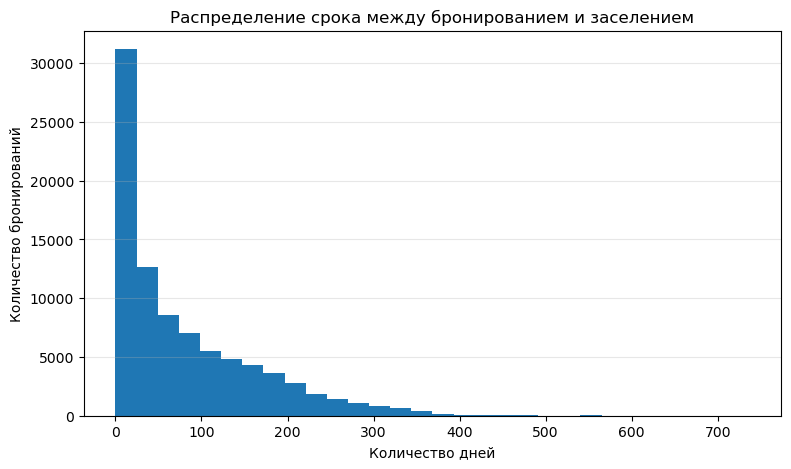

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(df['lead_time'], bins=30)
plt.title('Распределение срока между бронированием и заселением')
plt.xlabel('Количество дней')
plt.ylabel('Количество бронирований')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Бизнес-вывод

Срок между бронированием и заселением сильно различается. Этот признак потенциально важен для оценки риска отмены, поэтому он включён в модель.

# Этап 4. Диагностический анализ

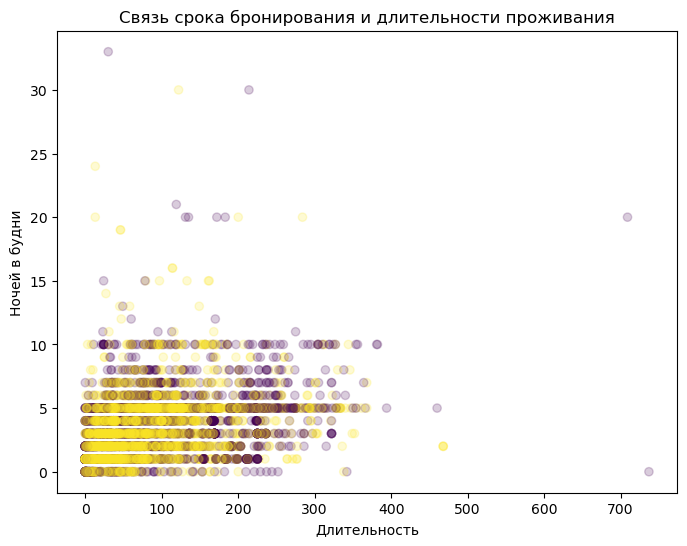

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(df['lead_time'].head(5000), df['stays_in_week_nights'].head(5000), c=df['is_canceled'].head(5000), alpha=0.2)
plt.title('Связь срока бронирования и длительности проживания')
plt.xlabel('Длительность')
plt.ylabel('Ночей в будни')
plt.show()

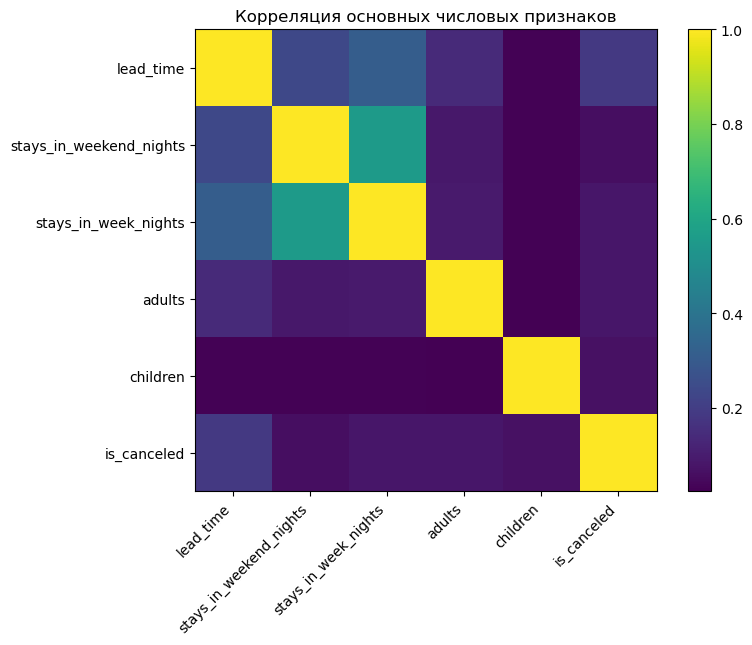

In [14]:
corr = df[['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'is_canceled']].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, interpolation='nearest')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Корреляция основных числовых признаков')
plt.colorbar()
plt.show()

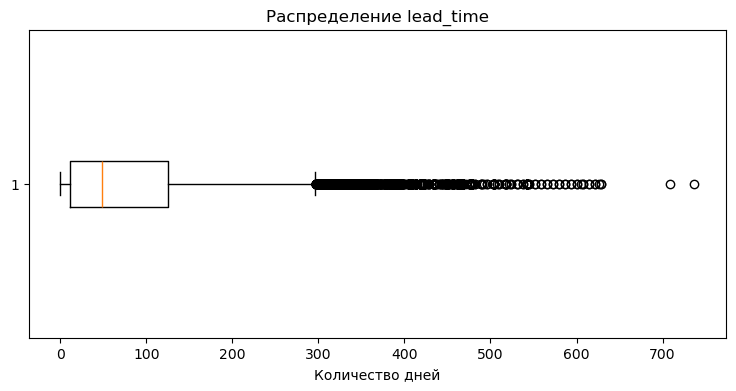

In [15]:
plt.figure(figsize=(9, 4))
plt.boxplot(df['lead_time'], vert=False)
plt.title('Распределение lead_time')
plt.xlabel('Количество дней')
plt.show()

### Бизнес-вывод

По отдельным признакам можно увидеть различия в поведении бронирований, но взаимосвязи недостаточно, чтобы принимать решение об овербукинге вручную. Поэтому следующий этап — построение модели.

# Этап 5. Логистическая регрессия и прогнозирование

Для модели используются признаки, которые могут быть известны до заселения клиента. Целевая переменная `is_canceled` показывает, произошло ли отменённое бронирование.

In [16]:
X = df[[
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'booking_changes',
    'days_in_waiting_list',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests'
]]
Y = df['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

In [18]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train.values.ravel())

Y_predicted = log_reg.predict(X_test)
Y_probability = log_reg.predict_proba(X_test)[:, 1]

print(f'Accuracy: {accuracy_score(y_test, Y_predicted):.2f}')
print(f'Precision: {precision_score(y_test, Y_predicted):.2f}')
print(f'Recall: {recall_score(y_test, Y_predicted):.2f}')
print(f'ROC-AUC: {roc_auc_score(y_test, Y_probability):.2f}')

Accuracy: 0.75
Precision: 0.65
Recall: 0.21
ROC-AUC: 0.74


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [19]:
result = X_test.copy()
result['actual_canceled'] = y_test.values
result['cancellation_probability'] = Y_probability
result['predicted_canceled'] = Y_predicted

result.head()

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,actual_canceled,cancellation_probability,predicted_canceled
30647,21,1,1,2,0.0,0,0,0,0,0,0,45.00,0,0,0,0.223303,0
1062,47,0,3,2,0.0,0,0,0,0,0,0,157.08,0,2,0,0.231874,0
30279,0,1,1,1,0.0,0,1,0,0,1,0,108.00,1,0,0,0.000283,0
48772,123,0,3,2,0.0,0,0,0,0,0,0,89.92,0,0,1,0.393046,0
17769,0,0,1,1,0.0,0,0,0,0,0,0,56.00,0,0,0,0.202333,0


### Бизнес-вывод

Модель позволяет получить для каждого бронирования вероятность отмены, а не только бинарный прогноз. Это делает результат более пригодным для дальнейшего использования в бизнес-процессе: бронирования можно дополнительно анализировать по уровню риска.

При этом текущая модель является учебной. Для автоматического определения объёма овербукинга необходимо дополнительно учитывать вместимость отеля и стоимость ошибки.

# Итоговый бизнес-вывод

1. В исходных данных 119 390 бронирований, из которых около 37% были отменены.
2. После удаления полных дубликатов для анализа осталось 87 396 наблюдений.
3. Логистическая регрессия позволяет прогнозировать отмену и рассчитывать индивидуальную вероятность отмены через `predict_proba`.
4. Для задачи овербукинга одной Accuracy недостаточно: решение зависит от стоимости недопродажи номера и стоимости ситуации, когда клиенту не хватит номера.
5. Следующий этап развития проекта — подобрать порог вероятности отмены и связать прогноз с экономикой отеля: количеством доступных номеров, стоимостью размещения и допустимым риском.

**Вывод:** проект демонстрирует полный аналитический цикл от подготовки данных до ML-прогноза и переводит результат модели в понятную бизнес-задачу.